# EDPs no domínio da STFT — ver e entender um áudio pt-BR "difundindo" no espectrograma

**Objetivo:** pegar uma gravação de fala em português, transformá-la numa *imagem* (espectrograma) com a
Transformada de Fourier de Curta Duração (STFT), deixar uma **equação diferencial parcial (EDP)** agir sobre
essa imagem, voltar para o áudio e **comparar** (visual e numericamente).

**Roteiro**
1. Escolher o áudio (Hugging Face / arquivo seu / sinal sintético de teste)
2. STFT: de onda 1-D para imagem 2-D
3. O compromisso tempo × frequência (tamanho da janela)
4. Magnitude e fase: por que a EDP mexe só na magnitude
5. As EDPs: calor e Perona-Malik (a matemática e o código)
6. A EDP evoluindo, passo a passo
7. Reconstrução (ISTFT) e comparação com ruído controlado
8. Inconsistência da STFT (o que pedimos × o que obtemos)
9. Quantas iterações? Métricas
10. Leitura crítica e próximos passos

## 0. Preparação

In [1]:
# --- Só no Google Colab: instale as dependências e (se preciso) suba edp_lab.py ---
# !pip -q install librosa soundfile matplotlib pandas pystoi huggingface_hub

In [2]:
# (desativado) %%writefile edp_lab.py - o notebook usa o edp_lab.py do disco\n"""
edp_lab.py — Laboratório: STFT + EDPs (Calor e Perona-Malik) em áudio de fala pt-BR.

Ideia central
-------------
    áudio x(t) --STFT--> X(t,f) = |X| · e^{jφ}
    |X| (em dB)  vira uma "imagem"  u(t,f)
    u evolui segundo uma EDP (calor ou Perona-Malik)   ->   u'
    áudio' = ISTFT( 10^{u'/20} · e^{jφ} )      (a fase φ original é mantida)

Tudo aqui é função pura, para ser usada tanto pelo script (run_lab.py)
quanto pelo notebook.
"""
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf

# ----------------------------------------------------------------------
# Parâmetros padrão (fala a 16 kHz: janela de 32 ms, passo de 8 ms)
# ----------------------------------------------------------------------
SR = 16000
N_FFT = 512
HOP = 128
PISO_DB = -80.0          # faixa dinâmica exibida nos gráficos (0 a -80 dB)

# Paleta categórica (azul, laranja, verde-água) — slots 1-3 de uma paleta validada
COR_ORIG = "#2a78d6"
COR_CALOR = "#eb6834"
COR_PM = "#1baf7a"
COR_TXT = "#0b0b0b"
COR_TXT2 = "#52514e"


def _estilo():
    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COR_TXT2,
        "xtick.color": COR_TXT2, "ytick.color": COR_TXT2,
        "text.color": COR_TXT, "axes.titlesize": 11, "axes.titleweight": "bold",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8,
        "font.size": 10, "figure.dpi": 110, "savefig.dpi": 150,
        "legend.frameon": False,
    })


_estilo()


# ----------------------------------------------------------------------
# 1. Dados: carregar áudio, baixar do Hugging Face, sintetizar para teste
# ----------------------------------------------------------------------
def carregar_audio(caminho, sr=SR, duracao=4.0, offset=0.0):
    """Carrega mono, reamostra para `sr`, recorta `duracao` s e normaliza o pico a 0.9."""
    y, _ = librosa.load(str(caminho), sr=sr, mono=True, offset=offset, duration=duracao)
    y = y - np.mean(y)
    pico = np.max(np.abs(y)) + 1e-12
    return (0.9 * y / pico).astype(np.float32)


def listar_audios_pasta(pasta, n=5, extensoes=(".wav", ".flac", ".mp3", ".ogg")):
    """Procura áudios numa pasta local (recursivo), em ordem alfabética, e devolve os `n` primeiros."""
    p = Path(pasta)
    if not p.exists():
        raise FileNotFoundError(f"Pasta não encontrada: {p.resolve()}")
    achados = sorted(str(f) for f in p.rglob("*") if f.suffix.lower() in extensoes)
    if not achados:
        raise FileNotFoundError(f"Nenhum áudio {extensoes} em {p.resolve()}")
    return achados[:n]


def listar_repo_hf(repo_id, max_itens=40):
    """Mostra o que há no repositório (útil quando o download automático não acha áudio)."""
    from collections import Counter
    from huggingface_hub import HfApi

    arquivos = HfApi().list_repo_files(repo_id, repo_type="dataset")
    print(f"{repo_id}: {len(arquivos)} arquivos")
    print("Extensões:", dict(Counter(Path(f).suffix.lower() or "(sem)" for f in arquivos)))
    for f in sorted(arquivos)[:max_itens]:
        print("  ", f)
    return arquivos


def _extrair_audio_parquet(caminho_parquet, destino, n):
    """Em datasets HF o áudio costuma vir em .parquet, numa coluna {bytes, path}. Salva `n` linhas como arquivos."""
    import pyarrow.parquet as pq

    tabela = pq.ParquetFile(caminho_parquet).read_row_group(0)
    col = next((c for c in tabela.column_names
                if str(tabela.schema.field(c).type).startswith("struct") and "bytes" in str(tabela.schema.field(c).type)), None)
    if col is None:
        raise RuntimeError(f"{caminho_parquet}: nenhuma coluna de áudio {{bytes, path}}. Colunas: {tabela.column_names}")
    saidas = []
    for i, item in enumerate(tabela.column(col).to_pylist()[:n]):
        ext = Path(item.get("path") or "x.wav").suffix or ".wav"
        p = Path(destino) / f"{Path(caminho_parquet).stem}_{i:03d}{ext}"
        p.write_bytes(item["bytes"])
        saidas.append(str(p))
    return saidas


def baixar_amostras_hf(repo_id="falabrasil/lapsbm", n=5, destino="data/hf",
                       extensoes=(".wav", ".flac", ".mp3", ".ogg")):
    """
    Baixa só `n` áudios de um dataset do Hugging Face Hub, sem baixar o dataset inteiro.
      1) se o repo tem arquivos de áudio soltos, baixa os `n` primeiros;
      2) senão, se tem .parquet (formato comum), baixa o primeiro e extrai `n` áudios dele.
    Se nada servir, lista o conteúdo do repositório para você inspecionar.
    Datasets FalaBrasil (desde jul/2025): https://huggingface.co/falabrasil
    """
    from huggingface_hub import HfApi, hf_hub_download

    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    try:
        todos = HfApi().list_repo_files(repo_id, repo_type="dataset")
    except Exception as e:
        raise RuntimeError(
            f"Não consegui acessar '{repo_id}' no Hugging Face ({type(e).__name__}). "
            "Um 401/'Repository Not Found' significa que o id está errado, o repo é privado/gated ou exige login. "
            "Alternativa 100% local: baixe os áudios (ex.: git clone https://huggingface.co/datasets/falabrasil/lapsbm) "
            "e use  --pasta <pasta>  ou  --audio arquivo.wav.") from e
    audios = sorted(f for f in todos if f.lower().endswith(extensoes))
    if audios:
        return [hf_hub_download(repo_id, f, repo_type="dataset", local_dir=destino) for f in audios[:n]]
    parquets = sorted(f for f in todos if f.lower().endswith(".parquet"))
    if parquets:
        p = hf_hub_download(repo_id, parquets[0], repo_type="dataset", local_dir=destino)
        return _extrair_audio_parquet(p, destino, n)
    listar_repo_hf(repo_id)
    raise RuntimeError(f"Não achei áudio nem .parquet em {repo_id}. A lista acima mostra o que existe; "
                       "baixe um arquivo manualmente e use --audio.")


def audio_sintetico(sr=SR, duracao=4.0, seed=0):
    """
    Sinal "tipo fala" SÓ para teste de fumaça (NÃO substitui áudio real):
    trem de pulsos glóticos (f0 variando) filtrado por formantes de vogais,
    com envelopes de sílaba e uma fricativa (ruído) no meio.
    """
    from scipy.signal import lfilter

    rng = np.random.default_rng(seed)
    n = int(sr * duracao)
    t = np.arange(n) / sr
    f0 = 120 + 25 * np.sin(2 * np.pi * 0.7 * t)
    fase = 2 * np.pi * np.cumsum(f0) / sr
    fonte = np.sign(np.sin(fase)) * (np.sin(fase) > 0.95)          # pulsos estreitos
    fonte = fonte + 0.02 * rng.standard_normal(n)

    def ressoador(x, f, bw):
        r = np.exp(-np.pi * bw / sr)
        a = [1, -2 * r * np.cos(2 * np.pi * f / sr), r * r]
        return lfilter([1 - r], a, x)

    vogais = [(700, 1200, 2600), (300, 2300, 3000), (500, 1500, 2500), (320, 800, 2500)]
    seg = n // len(vogais)
    y = np.zeros(n)
    for i, (f1, f2, f3) in enumerate(vogais):
        s = slice(i * seg, (i + 1) * seg if i < len(vogais) - 1 else n)
        x = fonte[s]
        v = ressoador(x, f1, 90) + 0.6 * ressoador(x, f2, 110) + 0.3 * ressoador(x, f3, 150)
        env = np.hanning(len(v)) ** 0.5
        y[s] = v * env
    # fricativa "s" entre as vogais 2 e 3
    c = 2 * seg
    ruido = rng.standard_normal(int(0.18 * sr))
    ruido = lfilter(*__import__("scipy.signal", fromlist=["butter"]).butter(4, 4500 / (sr / 2), "high"), ruido)
    y[c - len(ruido) // 2: c - len(ruido) // 2 + len(ruido)] += 0.15 * ruido * np.hanning(len(ruido))
    y = y / (np.max(np.abs(y)) + 1e-12) * 0.9
    return y.astype(np.float32)


def adicionar_ruido(y, snr_alvo_db, seed=0):
    """Soma ruído branco gaussiano de modo que SNR = snr_alvo_db (potência média)."""
    rng = np.random.default_rng(seed)
    p_sinal = np.mean(y.astype(np.float64) ** 2)
    p_ruido = p_sinal / (10 ** (snr_alvo_db / 10))
    return (y + rng.normal(0, np.sqrt(p_ruido), size=y.shape)).astype(np.float32)


# ----------------------------------------------------------------------
# 2. STFT e escala em dB
# ----------------------------------------------------------------------
@dataclass
class Espectro:
    mag: np.ndarray        # |X|  (freq x tempo)
    fase: np.ndarray       # φ
    ref: float             # amplitude de referência (0 dB)


def stft(y, n_fft=N_FFT, hop=HOP):
    X = librosa.stft(y, n_fft=n_fft, hop_length=hop, window="hann")
    mag = np.abs(X)
    return Espectro(mag=mag, fase=np.angle(X), ref=float(mag.max()))


def para_db(mag, ref, piso=1e-7):
    """Amplitude -> dB relativo a `ref` (piso evita log(0); é uma escala quase sem corte)."""
    return 20 * np.log10(np.maximum(mag / ref, piso))


def de_db(db, ref):
    return ref * 10 ** (db / 20)


def istft(mag, fase, n, hop=HOP, n_fft=N_FFT):
    return librosa.istft(mag * np.exp(1j * fase), hop_length=hop, n_fft=n_fft, window="hann", length=n)


def espec_db_de_sinal(y, ref, n_fft=N_FFT, hop=HOP):
    """Espectrograma em dB de um sinal, na MESMA referência (comparável entre sinais)."""
    mag = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop, window="hann"))
    return para_db(mag, ref)


# ----------------------------------------------------------------------
# 3. As EDPs (diferenças finitas, esquema explícito, bordas espelhadas)
# ----------------------------------------------------------------------
def _vizinhos(u):
    p = np.pad(u, 1, mode="edge")                  # replica a borda (sem "wrap-around")
    return p[:-2, 1:-1] - u, p[2:, 1:-1] - u, p[1:-1, :-2] - u, p[1:-1, 2:] - u


def equacao_calor(u, D=0.2, n_iter=10, historico=None, mascara=None):
    """
        ∂u/∂τ = D · (∂²u/∂t² + ∂²u/∂f²)        ->   u ← u + D · Δu
    Estável se D ≤ 0.25 (condição CFL em 2D). `historico`: lista p/ guardar instantâneos.
    """
    if D > 0.25:
        raise ValueError("D deve ser <= 0.25 (estabilidade numérica)")
    u = u.astype(np.float64).copy()
    if historico is not None:
        historico.append(u.copy())
    for _ in range(n_iter):
        dN, dS, dW, dE = _vizinhos(u)
        passo = D * (dN + dS + dW + dE)            # soma das diferenças = Laplaciano discreto
        u = u + (passo if mascara is None else mascara * passo)
        if historico is not None:
            historico.append(u.copy())
    return u


def perona_malik(u, kappa=10.0, dt=0.2, n_iter=10, funcao=1, historico=None, mascara=None):
    """
        ∂u/∂τ = div( c(|∇u|) ∇u )
    c grande onde o gradiente é pequeno (região lisa/ruído)  -> suaviza;
    c pequeno onde o gradiente é grande (borda: harmônico, transiente) -> preserva.
        funcao=1: c(g) = exp(-(g/κ)²)      funcao=2: c(g) = 1/(1+(g/κ)²)
    κ está em dB (mesma unidade de u).  Estável se dt ≤ 0.25.
    `mascara` (0..1, mesmo formato de u): onde vale 0 a EDP não age; onde vale 1 age por inteiro.
    """
    if dt > 0.25:
        raise ValueError("dt deve ser <= 0.25 (estabilidade numérica)")
    c = (lambda g: np.exp(-(g / kappa) ** 2)) if funcao == 1 else (lambda g: 1.0 / (1.0 + (g / kappa) ** 2))
    u = u.astype(np.float64).copy()
    if historico is not None:
        historico.append(u.copy())
    for _ in range(n_iter):
        dN, dS, dW, dE = _vizinhos(u)
        passo = dt * (c(dN) * dN + c(dS) * dS + c(dW) * dW + c(dE) * dE)
        u = u + (passo if mascara is None else mascara * passo)
        if historico is not None:
            historico.append(u.copy())
    return u


METODOS = {"calor": equacao_calor, "perona_malik": perona_malik}


# ----------------------------------------------------------------------
# 4. Pipeline completo: STFT -> (redução de ruído) -> EDP -> ISTFT
# ----------------------------------------------------------------------
def estimar_ruido(mag, frac=0.1):
    """
    Potência do ruído por bin de frequência, estimada nos `frac` quadros de MENOR energia
    (as pausas da fala). Hipótese: o ruído é estacionário e há pausas no áudio.
    """
    energia = np.sum(mag ** 2, axis=0)
    k = max(1, int(frac * mag.shape[1]))
    idx = np.argsort(energia)[:k]
    return np.mean(mag[:, idx] ** 2, axis=1)


def ganho_reducao(mag, Pn, tipo="wiener", alpha=1.0, piso=0.1, suavizar_t=3):
    """
    Ganho espectral por bin (0..1), multiplicado à magnitude.
      "wiener"   : G = ξ/(1+ξ), ξ = max(Py/Pn − 1, 0)       (SNR a priori, estimativa simples)
      "subtracao": G = sqrt(max(1 − α·Pn/Py, 0))            (subtração espectral de potência)
    `piso` limita a atenuação máxima (evita zerar bins); `suavizar_t` suaviza Py no tempo
    para reduzir o "ruído musical".
    """
    from scipy.ndimage import uniform_filter1d
    Py = uniform_filter1d(mag ** 2, size=suavizar_t, axis=1) if suavizar_t > 1 else mag ** 2
    Pn = np.maximum(Pn, 1e-20)[:, None]
    Py = np.maximum(Py, 1e-20)
    if tipo == "subtracao":
        g = np.sqrt(np.maximum(1 - alpha * Pn / Py, 0))
    else:
        xi = np.maximum(Py / Pn - 1, 0)
        g = xi / (1 + xi)
    return np.maximum(g, piso)


def mascara_ruido(u_db, Pn, ref, margem=8.0, largura=2.0):
    """
    Máscara suave (0..1): ~1 onde o espectrograma está perto/abaixo do piso de ruído (+`margem` dB),
    ~0 onde está bem acima (fala). Assim a EDP suaviza só as regiões dominadas por ruído.
    """
    piso_db = 10 * np.log10(np.maximum(Pn, 1e-20) / ref ** 2)[:, None]
    return 1.0 / (1.0 + np.exp(-(piso_db + margem - u_db) / largura))


def igualar_nivel(y_ref, y, teto=0.99):
    """Escala `y` para ter a mesma energia (RMS) de `y_ref` (comparação de escuta justa). Evita clipping."""
    g = np.sqrt(np.mean(y_ref.astype(np.float64) ** 2) / (np.mean(y.astype(np.float64) ** 2) + 1e-20))
    out = y * g
    pico = np.max(np.abs(out))
    if pico > teto:
        out = out * (teto / pico)
    return out.astype(np.float32)


def aplicar_edp(y, metodo="calor", n_fft=N_FFT, hop=HOP, pre=None, seletivo=False, margem=8.0, **kw):
    """
    Pipeline STFT -> [pre: redução de ruído] -> [EDP, opcionalmente só onde há ruído] -> ISTFT.

    metodo : "calor", "perona_malik" ou None (só o `pre`)
    pre    : None, "wiener" ou "subtracao"
    seletivo: se True, a EDP age só onde a máscara de ruído é ~1 (preserva a fala)
    Retorna dict:
      y_out : áudio reconstruído
      u_in  : espectrograma de entrada (dB)
      u_edp : espectrograma após o processamento (dB)   — o que pedimos
      u_re  : espectrograma (dB) do áudio reconstruído  — o que de fato resulta
      ref   : referência de 0 dB
    """
    E = stft(y, n_fft, hop)
    u_in = para_db(E.mag, E.ref)
    mag = E.mag
    if pre:
        mag = mag * ganho_reducao(mag, estimar_ruido(E.mag), pre)
    u0 = para_db(mag, E.ref)
    if metodo is None:
        u_edp = u0
    else:
        if seletivo:
            kw = dict(kw, mascara=mascara_ruido(u0, estimar_ruido(E.mag), E.ref, margem))
        u_edp = METODOS[metodo](u0, **kw)
    y_out = istft(de_db(u_edp, E.ref), E.fase, len(y), hop, n_fft)
    u_re = espec_db_de_sinal(y_out, E.ref, n_fft, hop)
    return dict(y_out=y_out.astype(np.float32), u_in=u_in, u_edp=u_edp, u_re=u_re, ref=E.ref)


def variantes(y_ruid, D=0.2, kappa=10.0, dt=0.2, n_iter=3, n_iter_sel=10):
    """Todos os métodos comparados, aplicados ao mesmo áudio ruidoso. Retorna {nome: resultado}."""
    return {
        "calor": aplicar_edp(y_ruid, "calor", D=D, n_iter=n_iter),
        "perona_malik": aplicar_edp(y_ruid, "perona_malik", kappa=kappa, dt=dt, n_iter=n_iter),
        "wiener": aplicar_edp(y_ruid, None, pre="wiener"),
        "wiener+pm": aplicar_edp(y_ruid, "perona_malik", pre="wiener", kappa=kappa, dt=dt, n_iter=n_iter),
        "pm_seletivo": aplicar_edp(y_ruid, "perona_malik", seletivo=True, kappa=kappa, dt=dt, n_iter=n_iter_sel),
    }


# ----------------------------------------------------------------------
# 5. Métricas
# ----------------------------------------------------------------------
def snr_db(ref, y):
    """SNR (dB) de `y` em relação ao sinal limpo `ref`."""
    r = ref.astype(np.float64)
    e = r - y.astype(np.float64)
    return float(10 * np.log10(np.sum(r ** 2) / (np.sum(e ** 2) + 1e-20)))


def lsd_db(y_ref, y, ref_amp, piso=PISO_DB):
    """Distância log-espectral (dB): média sobre os quadros da raiz do erro quadrático médio em dB."""
    A = np.maximum(espec_db_de_sinal(y_ref, ref_amp), piso)
    B = np.maximum(espec_db_de_sinal(y, ref_amp), piso)
    return float(np.mean(np.sqrt(np.mean((A - B) ** 2, axis=0))))


def stoi_ou_nan(y_ref, y, sr=SR):
    """Inteligibilidade (0..1, maior = melhor). NaN se `pystoi` não estiver instalado."""
    try:
        from pystoi import stoi
        return float(stoi(y_ref, y, sr, extended=False))
    except Exception:
        return float("nan")


def metricas(y_limpo, y, ref_amp):
    return dict(SNR_dB=snr_db(y_limpo, y), LSD_dB=lsd_db(y_limpo, y, ref_amp), STOI=stoi_ou_nan(y_limpo, y))


# ----------------------------------------------------------------------
# 6. Gráficos (cada um responde a UMA pergunta)
# ----------------------------------------------------------------------
def _spec(ax, S_db, sr=SR, hop=HOP, titulo="", vmin=PISO_DB, vmax=0, cmap="magma", y_axis="linear"):
    im = librosa.display.specshow(S_db, sr=sr, hop_length=hop, x_axis="time", y_axis=y_axis,
                                  ax=ax, vmin=vmin, vmax=vmax, cmap=cmap, rasterized=True)
    ax.set_title(titulo)
    ax.grid(False)
    ax.set_xlabel("Tempo (s)")
    ax.set_ylabel("Frequência (Hz)")
    return im


def _salvar(fig, saida):
    if saida:
        Path(saida).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(saida, bbox_inches="tight")
    return fig


def fig_onda_e_espectrograma(y, sr=SR, saida=None):
    """Pergunta: o que a STFT faz com o sinal? Onda 1-D (tempo) -> imagem 2-D (tempo × frequência)."""
    E = stft(y)
    S = para_db(E.mag, E.ref)
    fig, (a, b) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw=dict(height_ratios=[1, 2]))
    t = np.arange(len(y)) / sr
    a.plot(t, y, color=COR_ORIG, lw=0.6)
    a.set_title("Domínio do tempo: x(t) — uma série 1-D")
    a.set_ylabel("Amplitude")
    im = _spec(b, S, sr, titulo="Domínio tempo-frequência: |X(t,f)| em dB — uma imagem 2-D")
    fig.colorbar(im, ax=[a, b], label="dB (0 = máximo)", pad=0.01)
    a.set_xlabel("")
    return _salvar(fig, saida)


def fig_resolucao_stft(y, sr=SR, saida=None, janelas=(128, 512, 2048)):
    """Pergunta: como a janela da STFT muda a imagem? (princípio de incerteza tempo × frequência)."""
    fig, axs = plt.subplots(1, len(janelas), figsize=(5 * len(janelas), 4), sharey=True)
    for ax, nf in zip(np.atleast_1d(axs), janelas):
        E = stft(y, n_fft=nf, hop=nf // 4)
        im = _spec(ax, para_db(E.mag, E.ref), sr, hop=nf // 4,
                   titulo=f"n_fft={nf}  (janela {1000 * nf / sr:.0f} ms)")
    fig.suptitle("Janela curta: bom no tempo, borrado na frequência • Janela longa: o inverso", y=1.02, fontsize=11)
    fig.colorbar(im, ax=axs, label="dB", pad=0.01)
    return _salvar(fig, saida)


def fig_magnitude_fase(y, sr=SR, saida=None):
    """Pergunta: por que mantemos a fase? Reconstrói com fase original, aleatória e zero."""
    E = stft(y)
    rng = np.random.default_rng(0)
    casos = {
        "Fase original": E.fase,
        "Fase aleatória": rng.uniform(-np.pi, np.pi, E.fase.shape),
        "Fase zero": np.zeros_like(E.fase),
    }
    fig, axs = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
    im = _spec(axs[0], para_db(E.mag, E.ref), sr, titulo="|X| (magnitude, em dB)")
    ys = {}
    for ax, (nome, ph) in zip(axs[1:], casos.items()):
        yr = istft(E.mag, ph, len(y))
        ys[nome] = yr
        _spec(ax, espec_db_de_sinal(yr, E.ref), sr, titulo=f"{nome}  →  SNR {snr_db(y, yr):.1f} dB")
    fig.suptitle("A EDP altera só |X|. A fase carrega o alinhamento temporal: sem ela o som se desfaz", y=1.03, fontsize=11)
    fig.colorbar(im, ax=axs, label="dB", pad=0.01)
    _salvar(fig, saida)
    return fig, ys


def fig_evolucao_edp(y, sr=SR, saida=None, passos=(0, 5, 20, 80), D=0.2, kappa=10.0, dt=0.2):
    """Pergunta: o que 'difundir' faz à imagem? Instantâneos da evolução do calor e do Perona-Malik."""
    E = stft(y)
    u0 = para_db(E.mag, E.ref)
    h_c, h_p = [], []
    equacao_calor(u0, D=D, n_iter=max(passos), historico=h_c)
    perona_malik(u0, kappa=kappa, dt=dt, n_iter=max(passos), historico=h_p)
    fig, axs = plt.subplots(2, len(passos), figsize=(4.6 * len(passos), 7.2), sharex=True, sharey=True)
    for j, k in enumerate(passos):
        _spec(axs[0, j], h_c[k], sr, titulo=f"Calor — {k} iterações")
        im = _spec(axs[1, j], h_p[k], sr, titulo=f"Perona-Malik — {k} iterações")
    fig.colorbar(im, ax=axs, label="dB", pad=0.01)
    return _salvar(fig, saida)


def fig_funcao_difusao(kappa=10.0, saida=None):
    """Pergunta: por que o Perona-Malik preserva bordas? Mostra c(g) e o fluxo c(g)·g."""
    g = np.linspace(0, 6 * kappa, 400)
    c1, c2 = np.exp(-(g / kappa) ** 2), 1 / (1 + (g / kappa) ** 2)
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
    a.plot(g, c1, color=COR_PM, lw=2, label="c₁ = exp(−(g/κ)²)")
    a.plot(g, c2, color=COR_CALOR, lw=2, label="c₂ = 1/(1+(g/κ)²)")
    a.axhline(1, color=COR_ORIG, lw=1.5, ls="--", label="Calor: c = 1 (sempre)")
    a.set_xlabel("|gradiente| g (dB entre vizinhos)"); a.set_ylabel("coeficiente de difusão c(g)")
    a.set_title("Quanto difunde, em função da diferença local"); a.legend()
    b.plot(g, c1 * g, color=COR_PM, lw=2, label="fluxo c₁·g")
    b.plot(g, c2 * g, color=COR_CALOR, lw=2, label="fluxo c₂·g")
    b.plot(g, g, color=COR_ORIG, lw=1.5, ls="--", label="Calor: g")
    b.set_xlabel("|gradiente| g (dB)"); b.set_ylabel("fluxo de energia c(g)·g")
    b.set_title("Fluxo cai para g grande ⇒ bordas sobrevivem"); b.legend()
    return _salvar(fig, saida)


def fig_comparacao(y_limpo, y_ruidoso, res_calor, res_pm, sr=SR, saida=None, rotulo="Com ruído"):
    """Figura principal: original × ruidoso × calor × Perona-Malik, diferenças e perfil espectral."""
    ref = res_calor["ref"]
    S_limpo = espec_db_de_sinal(y_limpo, ref)
    S_ruid = res_calor["u_in"]
    S_c, S_p = res_calor["u_re"], res_pm["u_re"]
    fig, axs = plt.subplots(2, 4, figsize=(22, 8.5), sharex=True)
    _spec(axs[0, 0], S_limpo, sr, titulo="Referência limpa")
    _spec(axs[0, 1], S_ruid, sr, titulo=rotulo)
    _spec(axs[0, 2], S_c, sr, titulo="Após Calor")
    im = _spec(axs[0, 3], S_p, sr, titulo="Após Perona-Malik")
    fig.colorbar(im, ax=axs[0, :], label="dB", pad=0.01, shrink=0.9)
    lim = 40
    axs[1, 0].axis("off")
    _spec(axs[1, 1], S_ruid - S_limpo, sr, titulo="Erro do ruidoso (ruidoso − limpo)", vmin=-lim, vmax=lim, cmap="coolwarm")
    _spec(axs[1, 2], S_c - S_limpo, sr, titulo="Erro após Calor (− limpo)", vmin=-lim, vmax=lim, cmap="coolwarm")
    im2 = _spec(axs[1, 3], S_p - S_limpo, sr, titulo="Erro após Perona-Malik (− limpo)", vmin=-lim, vmax=lim, cmap="coolwarm")
    fig.colorbar(im2, ax=axs[1, 1:], label="Δ dB  (vermelho = sobrou energia, azul = faltou)", pad=0.01, shrink=0.9)
    return _salvar(fig, saida)


def fig_perfil_espectral(y_limpo, y_ruidoso, y_calor, y_pm, sr=SR, ref=None, saida=None):
    """Pergunta: em quais frequências a EDP mexeu? Magnitude média por frequência + um quadro isolado."""
    ref = ref or stft(y_limpo).ref
    freqs = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)
    sinais = [("Limpo", y_limpo, "#52514e", "-"), ("Ruidoso", y_ruidoso, COR_ORIG, "-"),
              ("Calor", y_calor, COR_CALOR, "-"), ("Perona-Malik", y_pm, COR_PM, "-")]
    S = {n: espec_db_de_sinal(y, ref) for n, y, _, _ in sinais}
    # quadro de maior energia do sinal limpo (uma vogal, onde os harmônicos aparecem)
    q = int(np.argmax(np.sum(10 ** (S["Limpo"] / 10), axis=0)))
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.5))
    for n, _, c, ls in sinais:
        a.plot(freqs, S[n].mean(axis=1), color=c, lw=1.8, ls=ls, label=n)
        b.plot(freqs, S[n][:, q], color=c, lw=1.3, label=n)
    a.set_title("Magnitude média no tempo, por frequência"); b.set_title(f"Um único quadro (t = {q * HOP / sr:.2f} s): harmônicos")
    for ax in (a, b):
        ax.set_xlabel("Frequência (Hz)"); ax.set_ylabel("dB"); ax.legend(ncol=2)
    return _salvar(fig, saida)


def fig_consistencia(res, sr=SR, saida=None, titulo="Calor"):
    """Pergunta: a EDP 'saiu' como planejado? Compara o espectrograma pós-EDP com o do áudio reconstruído."""
    fig, axs = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    _spec(axs[0], res["u_edp"], sr, titulo=f"{titulo}: saída da EDP (o que pedimos)")
    im = _spec(axs[1], res["u_re"], sr, titulo="STFT do áudio reconstruído (o que obtemos)")
    _spec(axs[2], res["u_re"] - res["u_edp"], sr, titulo="Diferença (inconsistência da STFT)", vmin=-20, vmax=20, cmap="coolwarm")
    fig.colorbar(im, ax=axs, label="dB", pad=0.01)
    return _salvar(fig, saida)


def varredura_iteracoes(y_limpo, y_ruidoso, ref, iteracoes=(0, 1, 2, 3, 5, 10, 20, 40), D=0.2, kappa=10.0, dt=0.2):
    """Métricas × número de iterações, para cada EDP. Retorna DataFrame."""
    import pandas as pd
    linhas = []
    for k in iteracoes:
        for nome, kw in (("calor", dict(D=D, n_iter=k)), ("perona_malik", dict(kappa=kappa, dt=dt, n_iter=k)),
                         ("pm_seletivo", dict(kappa=kappa, dt=dt, n_iter=k))):
            r = aplicar_edp(y_ruidoso, "calor" if nome == "calor" else "perona_malik", seletivo=(nome == "pm_seletivo"), **kw)
            linhas.append(dict(metodo=nome, iteracoes=k, **metricas(y_limpo, r["y_out"], ref)))
    return pd.DataFrame(linhas)


def fig_curvas(df, saida=None, base=None):
    """Pergunta: quantas iterações valem a pena? SNR, LSD e STOI × iterações, para cada EDP."""
    cols = [("SNR_dB", "SNR (dB) ↑"), ("LSD_dB", "Distância log-espectral (dB) ↓"), ("STOI", "STOI ↑")]
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, (c, tit) in zip(axs, cols):
        for m in df.metodo.unique():
            d = df[df.metodo == m]
            ax.plot(d.iteracoes, d[c], color=CORES_VAR.get(m, "#52514e"), lw=2, marker="o", ms=5, label=ROTULOS_VAR.get(m, m))
        if base and c in base:
            ax.axhline(base[c], color=COR_ORIG, ls="--", lw=1.5, label="ruidoso (sem EDP)")
        ax.set_xlabel("Iterações da EDP"); ax.set_title(tit); ax.legend()
    return _salvar(fig, saida)


def salvar_wav(y, caminho, sr=SR):
    Path(caminho).parent.mkdir(parents=True, exist_ok=True)
    sf.write(str(caminho), y, sr)


# cores das variantes (paleta categórica; azul = ruidoso, laranja/verde = EDPs puras)
CORES_VAR = {"ruidoso": COR_ORIG, "calor": COR_CALOR, "perona_malik": COR_PM, "wiener": "#6250d6",
             "wiener+pm": "#e87ba4", "pm_seletivo": "#eda100"}
ROTULOS_VAR = {"ruidoso": "Ruidoso", "calor": "Calor", "perona_malik": "Perona-Malik", "wiener": "Wiener",
               "wiener+pm": "Wiener + PM", "pm_seletivo": "PM seletivo"}


def fig_variantes(y_limpo, y_ruid, res, sr=SR, saida=None, rotulo="Ruidoso"):
    """Todas as variantes lado a lado: espectrograma (linha 1) e erro contra o limpo (linha 2)."""
    ref = next(iter(res.values()))["ref"]
    S_limpo = espec_db_de_sinal(y_limpo, ref)
    S_ruid = espec_db_de_sinal(y_ruid, ref)
    paineis = [("Limpo (referência)", S_limpo), (rotulo, S_ruid)] + [(ROTULOS_VAR[k], v["u_re"]) for k, v in res.items()]
    n = len(paineis)
    fig, axs = plt.subplots(2, n, figsize=(3.9 * n, 7.6), sharex=True, sharey=True)
    for j, (nome, S) in enumerate(paineis):
        im = _spec(axs[0, j], S, sr, titulo=nome)
        if j == 0:
            axs[1, j].axis("off")
        else:
            im2 = _spec(axs[1, j], S - S_limpo, sr, titulo="erro vs. limpo", vmin=-40, vmax=40, cmap="coolwarm")
    fig.colorbar(im, ax=axs[0, :], label="dB", pad=0.01, shrink=0.9)
    fig.colorbar(im2, ax=axs[1, 1:], label="Δ dB (vermelho = sobrou energia, azul = faltou)", pad=0.01, shrink=0.9)
    return _salvar(fig, saida)


def fig_mascara(y, y_ruid, sr=SR, saida=None, margem=8.0):
    """Pergunta: ONDE a EDP seletiva age? Mostra o espectrograma ruidoso e a máscara (1 = suaviza, 0 = protege)."""
    E = stft(y_ruid)
    u = para_db(E.mag, E.ref)
    M = mascara_ruido(u, estimar_ruido(E.mag), E.ref, margem)
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
    _spec(axs[0], u, sr, titulo="Espectrograma ruidoso (dB)")
    im = _spec(axs[1], M, sr, titulo=f"Máscara (1 = a EDP age; 0 = protegido)  margem {margem:g} dB", vmin=0, vmax=1, cmap="viridis")
    fig.colorbar(im, ax=axs[1], pad=0.01)
    _spec(axs[2], u * (1 - M) + (-80) * M, sr, titulo="O que fica PROTEGIDO (regiões de fala)")
    return _salvar(fig, saida)

Overwriting edp_lab.py


In [3]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Audio, display
import edp_lab as L

## 1. Escolher o áudio

Fontes (as duas primeiras são **100% locais**):

* `"pasta"` — uma pasta sua com áudios (`.wav`, `.flac`, `.mp3`, `.ogg`), por exemplo um dataset já baixado ou gravações suas (`python gravar.py`).
* `"arquivo"` — um arquivo seu.
* `"hf"` — (opcional, precisa de internet) baixa poucos arquivos do Hugging Face. Ids que verifiquei: `falabrasil/lapsbm` (35 locutores, ~0,9 h) e
  `falabrasil/coddef` (≈ 1 h 25 min, 1 locutor). Outros datasets citados nos seus links: CETUC (144 h, só pesquisa), Constituição (9 h) e o **Tagarela** (arXiv 2603.15326).
* `"sintetico"` — sinal "tipo fala" gerado por código. **Serve só para testar o código**; não é fala real.

In [4]:
FONTE = "sintetico"          # "pasta" | "arquivo" | "hf" | "sintetico"
PASTA = "meus_audios"        # usado se FONTE = "pasta" (100% offline)
HF_REPO = "falabrasil/lapsbm"
ARQUIVO = "meu_audio.wav"
DURACAO = 4.0                # segundos analisados
INDICE = 0                   # qual dos arquivos baixados usar

y = None
try:
    if FONTE == "hf":
        caminhos = L.baixar_amostras_hf(HF_REPO, n=3)
        print("Arquivos:", caminhos)
        y = L.carregar_audio(caminhos[INDICE], duracao=DURACAO)
    elif FONTE == "pasta":
        caminhos = L.listar_audios_pasta(PASTA, n=5)
        print("Arquivos:", caminhos)
        y = L.carregar_audio(caminhos[INDICE], duracao=DURACAO)
    elif FONTE == "arquivo":
        y = L.carregar_audio(ARQUIVO, duracao=DURACAO)
except Exception as e:
    print("Não consegui carregar a fonte escolhida:", repr(e))
if y is None:
    print("Usando o sinal SINTÉTICO (apenas teste de código).")
    y = L.audio_sintetico(duracao=DURACAO)

print(f"{len(y)} amostras @ {L.SR} Hz = {len(y)/L.SR:.2f} s")
display(Audio(y, rate=L.SR))

Usando o sinal SINTÉTICO (apenas teste de código).


64000 amostras @ 16000 Hz = 4.00 s


## 2. STFT: de onda 1-D para imagem 2-D

Uma gravação é uma série $x[n]$. A STFT fatia o sinal em janelas curtas e sobrepostas, multiplica cada fatia por
uma janela $w$ (aqui, Hann) e aplica a Fourier em cada uma:

$$X(m,k)=\sum_{n} x[n+mH]\,w[n]\,e^{-j2\pi kn/N}$$

* $m$ = índice do quadro (tempo, passo $H$ = `HOP` = 128 amostras = 8 ms);
* $k$ = índice de frequência (bin), $N$ = `N_FFT` = 512 → resolução de $f_s/N$ = 31,25 Hz;
* $X$ é **complexo**: $X = |X|\,e^{j\varphi}$.

Mostramos $|X|$ em **dB** ($20\log_{10}$), porque o ouvido e a fala têm faixa dinâmica enorme — em escala linear só os picos apareceriam.
Na vertical, as **linhas horizontais** equidistantes são os *harmônicos* da voz (múltiplos da frequência fundamental $f_0$); as manchas
largas são os *formantes* (ressonâncias do trato vocal, que distinguem as vogais); consoantes fricativas (s, x, f) viram faixas verticais de
energia em altas frequências.

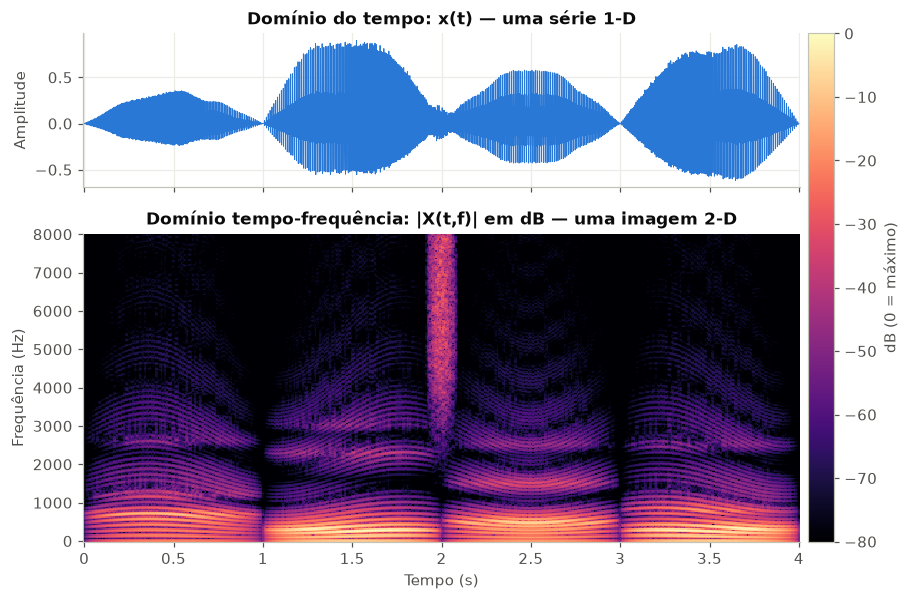

In [5]:
fig = L.fig_onda_e_espectrograma(y, saida="outputs/nb_01_onda_espectrograma.png"); plt.show()

## 3. O compromisso tempo × frequência

Não existe janela perfeita: janela **curta** localiza bem eventos no tempo mas "borra" frequências (os harmônicos somem);
janela **longa** resolve os harmônicos mas "borra" o tempo. É um limite da própria Fourier (princípio de incerteza,
$\Delta t\,\Delta f \gtrsim \tfrac{1}{4\pi}$). Para fala a 16 kHz, 20–40 ms (n_fft = 320–640) é a escolha clássica — por isso usamos 512.

Isso importa para as EDPs: **a EDP enxerga a imagem que a STFT produz**. Outra janela = outra imagem = outro resultado.

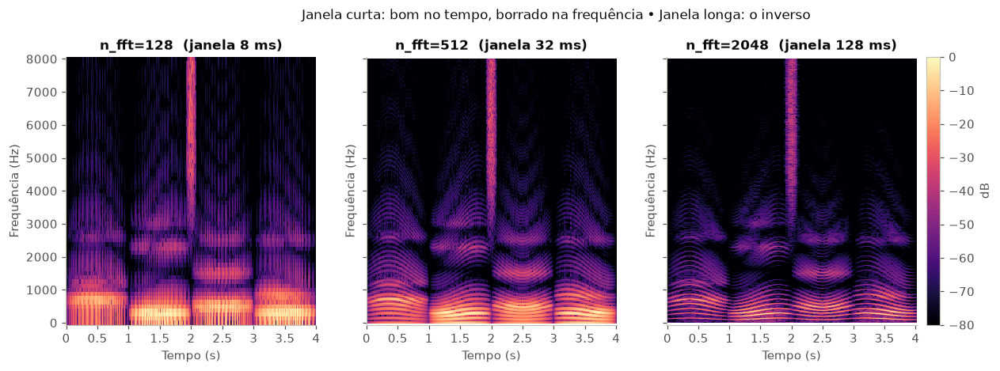

In [6]:
fig = L.fig_resolucao_stft(y, saida="outputs/nb_02_resolucao_stft.png"); plt.show()

## 4. Magnitude × fase: por que a EDP só toca em $|X|$

$|X|$ é uma imagem bonita e "suave" — dá para aplicar EDPs de processamento de imagem. A fase $\varphi$ parece ruído, mas carrega o
**alinhamento temporal** fino das ondas. Teste abaixo: com a magnitude original e **fase aleatória** ou **zero**, o áudio se desfaz
(SNR ≈ 0 dB ou pior). Por isso o pipeline mantém a fase original e só modifica a magnitude.

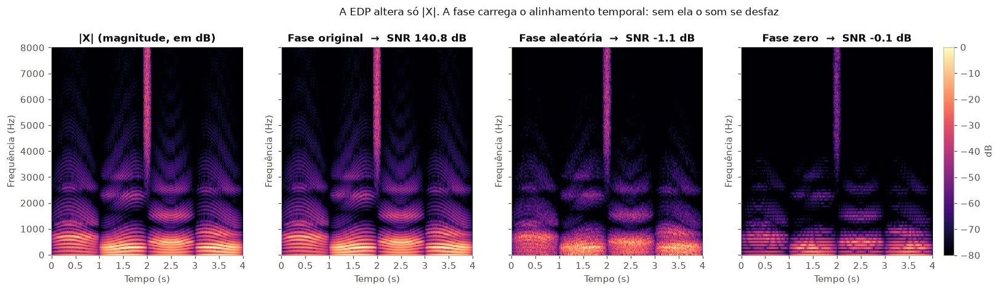

Fase original (deve ser ~idêntico):


Fase aleatória (rouco/ruidoso):


Fase zero (robótico/zumbido):


In [7]:
fig, ys = L.fig_magnitude_fase(y, saida="outputs/nb_03_magnitude_fase.png"); plt.show()
print("Fase original (deve ser ~idêntico):"); display(Audio(ys["Fase original"], rate=L.SR))
print("Fase aleatória (rouco/ruidoso):");      display(Audio(ys["Fase aleatória"], rate=L.SR))
print("Fase zero (robótico/zumbido):");        display(Audio(ys["Fase zero"], rate=L.SR))

## 5. As EDPs

Seja $u(t,f)$ a magnitude em dB (a "imagem"). Introduzimos um **tempo artificial** $\tau$ e deixamos $u$ evoluir.
Cada iteração é um passo de tamanho $\Delta\tau$ de um esquema explícito de diferenças finitas.

### 5.1 Equação do calor (difusão linear, isotrópica)

$$\frac{\partial u}{\partial \tau}=D\,\nabla^2 u=D\left(\frac{\partial^2 u}{\partial t^2}+\frac{\partial^2 u}{\partial f^2}\right)
\quad\Rightarrow\quad u \leftarrow u + D\,(u_N+u_S+u_W+u_E-4u)$$

Cada ponto caminha na direção da média dos 4 vizinhos. Tudo é suavizado **igualmente**: ruído *e* harmônicos *e* bordas.
Estabilidade: $D\le 1/4$. Equivale a um filtro gaussiano de largura crescente com $\tau$.

### 5.2 Perona-Malik (difusão anisotrópica, não linear)

$$\frac{\partial u}{\partial \tau}=\nabla\!\cdot\!\big(c(\|\nabla u\|)\,\nabla u\big),\qquad c(g)=e^{-(g/\kappa)^2}\ \text{ou}\ \frac{1}{1+(g/\kappa)^2}$$

O coeficiente $c$ **desliga a difusão onde o gradiente é grande** (bordas), então só regiões "lisas" são suavizadas.
$\kappa$ (em dB) é o limiar entre "variação pequena = ruído" e "variação grande = estrutura".

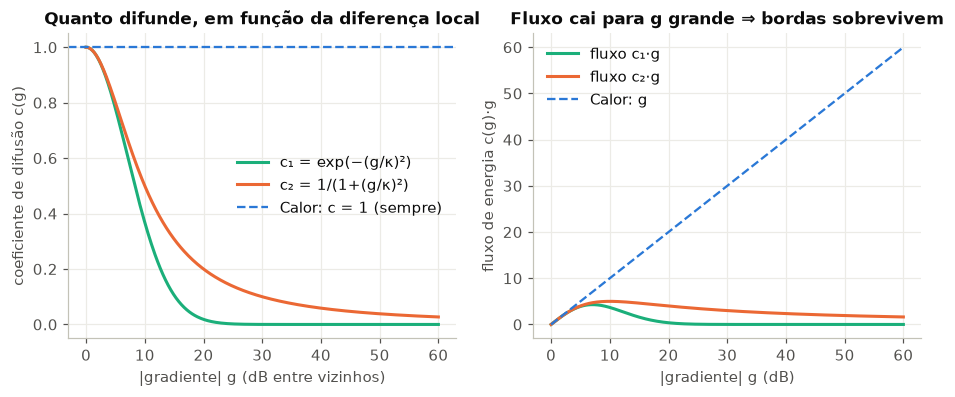

In [8]:
fig = L.fig_funcao_difusao(kappa=10.0, saida="outputs/nb_04_funcao_difusao.png"); plt.show()

No gráfico da direita: para o calor o fluxo cresce sempre com o gradiente (borda = muito fluxo = borra). No Perona-Malik o fluxo
**cai** depois de $g\approx\kappa$: diferenças grandes já não escoam. Esse é o mecanismo de "preservar bordas".

## 6. A EDP evoluindo, passo a passo

Aplicamos as EDPs num espectrograma **ruidoso** (ruído branco com SNR de 10 dB). Veja com 0, 5, 20 e 80 iterações.

Dois comportamentos a observar:
* **Calor:** o fundo ruidoso vira uma névoa lisa, mas os harmônicos viram uma mancha larga — a estrutura fina da voz se perde rápido.
* **Perona-Malik:** preserva melhor os harmônicos por mais iterações. Repare nos **pontinhos escuros** que aparecem: são "buracos" profundos do ruído
  (mínimos locais em dB) que têm gradiente enorme em volta; para a EDP eles parecem *bordas* e ficam protegidos. É um limite conhecido do método
  e é sensível a escolha de $\kappa$.

Áudio ruidoso:


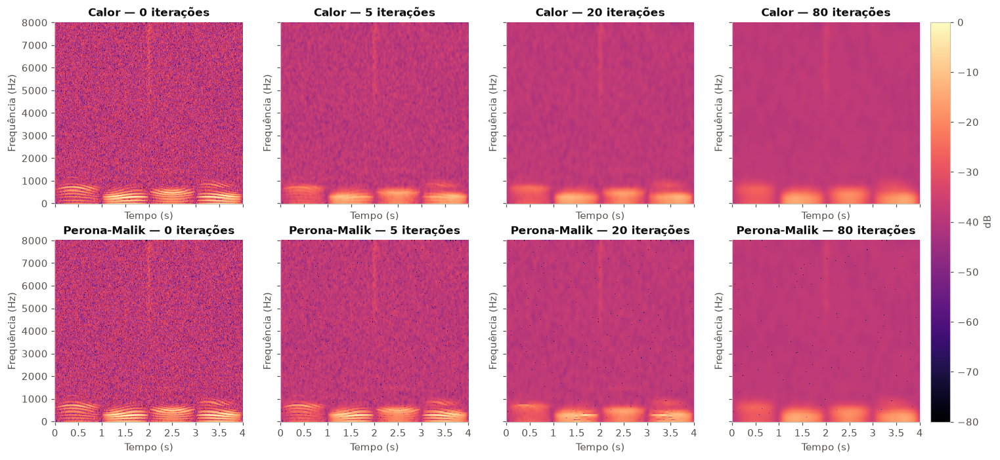

In [9]:
SNR_ENTRADA = 10
y_ruid = L.adicionar_ruido(y, SNR_ENTRADA)
print("Áudio ruidoso:"); display(Audio(y_ruid, rate=L.SR))
fig = L.fig_evolucao_edp(y_ruid, D=0.2, kappa=10.0, dt=0.2, saida="outputs/nb_05_evolucao_edp.png"); plt.show()

## 7. Reconstrução (ISTFT) e comparação

Pipeline completo:

$$x \xrightarrow{\text{STFT}} |X|e^{j\varphi}\ \xrightarrow{20\log_{10}}\ u\ \xrightarrow{\text{EDP}}\ u'\ \xrightarrow{10^{u'/20}}\ |X'|\ \xrightarrow{|X'|e^{j\varphi}\ +\ \text{ISTFT}}\ x'$$

Métricas (sempre contra o áudio **limpo** de referência):
* **SNR (dB)** — fidelidade da forma de onda (↑ melhor). É rigorosa: exige acertar a *fase*.
* **LSD (dB)** — distância log-espectral: diferença média entre espectrogramas em dB (↓ melhor). Mede só a *magnitude*.
* **STOI** — inteligibilidade prevista, 0 a 1 (↑ melhor). Foi feita para fala; em sinal sintético é só indicativa.

> **Número de iterações:** começamos com **3**, não 20 — a varredura da seção 9 mostra por quê.

,SNR_dB,LSD_dB,STOI
ruidoso,10.002,33.388,0.563
calor,5.825,31.796,0.538
perona_malik,10.301,32.110,0.566


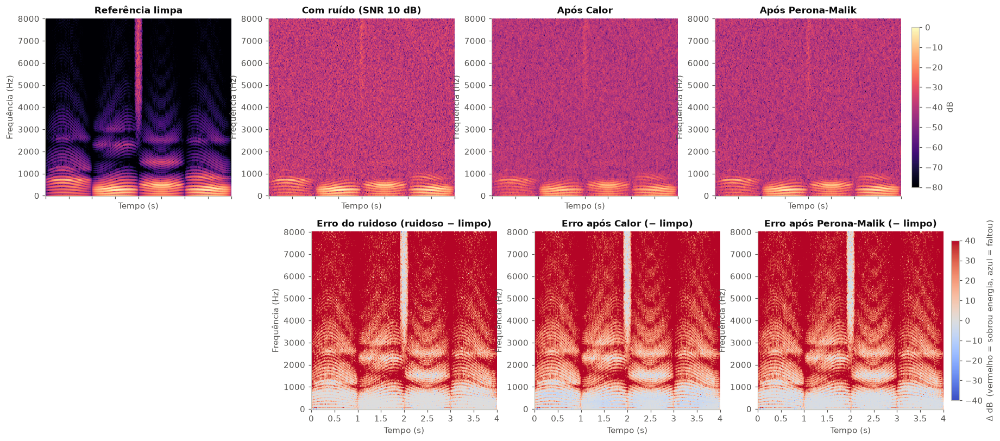

Limpo


Ruidoso


Calor


Perona-Malik


In [10]:
N_ITER = 3
ref = L.stft(y).ref
rc = L.aplicar_edp(y_ruid, "calor", D=0.2, n_iter=N_ITER)
rp = L.aplicar_edp(y_ruid, "perona_malik", kappa=10.0, dt=0.2, n_iter=N_ITER)

tab = pd.DataFrame({"ruidoso": L.metricas(y, y_ruid, ref),
                    "calor": L.metricas(y, rc["y_out"], ref),
                    "perona_malik": L.metricas(y, rp["y_out"], ref)}).T.round(3)
display(tab)

fig = L.fig_comparacao(y, y_ruid, rc, rp, rotulo=f"Com ruído (SNR {SNR_ENTRADA} dB)", saida="outputs/nb_06_comparacao.png"); plt.show()
for nome, s in (("Limpo", y), ("Ruidoso", y_ruid), ("Calor", rc["y_out"]), ("Perona-Malik", rp["y_out"])):
    print(nome); display(Audio(s, rate=L.SR))

**Como ler os mapas de erro** (linha de baixo): azul = a EDP/ruído *tirou* energia que existia; vermelho = *sobrou* energia que não existia
(ruído). Um bom denoiser deixa o mapa cinza-claro (erro ≈ 0). Em geral o ruído branco domina as altas frequências (região vermelha),
onde o sinal limpo tem pouquíssima energia. Em baixas frequências, o calor tende a ficar **azulado** nos harmônicos: ele os apagou.

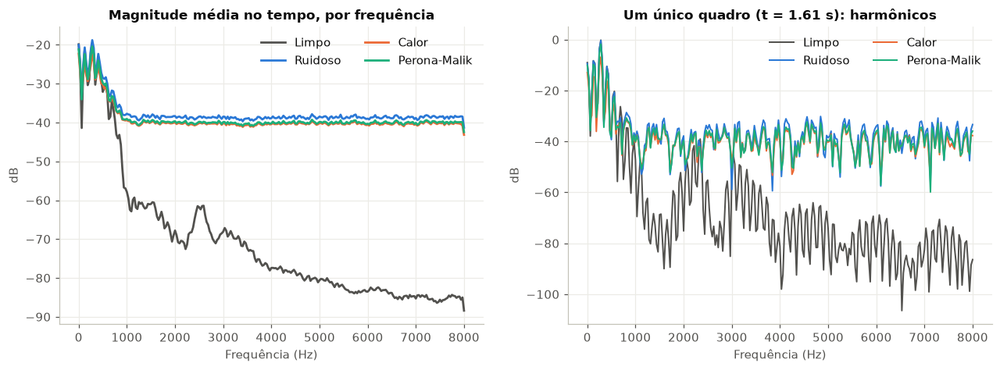

In [11]:
fig = L.fig_perfil_espectral(y, y_ruid, rc["y_out"], rp["y_out"], ref=ref, saida="outputs/nb_07_perfil_espectral.png"); plt.show()

## 8. O que pedimos × o que obtemos (consistência da STFT)

Nem toda matriz complexa é a STFT de algum sinal. Ao modificar $|X|$ mantendo $\varphi$, o resultado deixa de ser uma STFT "consistente";
a ISTFT acha o sinal cuja STFT é **a mais próxima** (mínimos quadrados). Por isso o espectrograma do áudio reconstruído difere do que a EDP entregou.
Toda a avaliação acima usa o espectrograma do **áudio reconstruído** (o que você de fato escutaria).

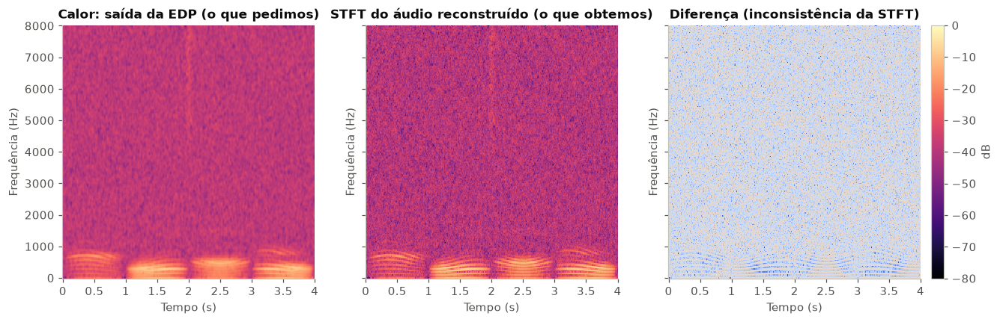

In [12]:
fig = L.fig_consistencia(rc, titulo="Calor", saida="outputs/nb_08_consistencia.png"); plt.show()

## 9. Quantas iterações? Varredura

Cada iteração suaviza mais. Há um ponto ótimo (remove ruído sem apagar a fala) e depois só destrói. Varremos 0 a 40 iterações.

,metodo,iteracoes,SNR_dB,LSD_dB,STOI
0,calor,0,10.002,33.388,0.563
1,perona_malik,0,10.002,33.388,0.563
2,pm_seletivo,0,10.002,33.388,0.563
3,calor,1,8.907,32.173,0.561
4,perona_malik,1,10.612,32.738,0.565
5,pm_seletivo,1,10.639,32.836,0.565
6,calor,2,6.887,31.921,0.550
7,perona_malik,2,10.600,32.343,0.566
8,pm_seletivo,2,11.089,32.491,0.568
9,calor,3,5.825,31.796,0.538


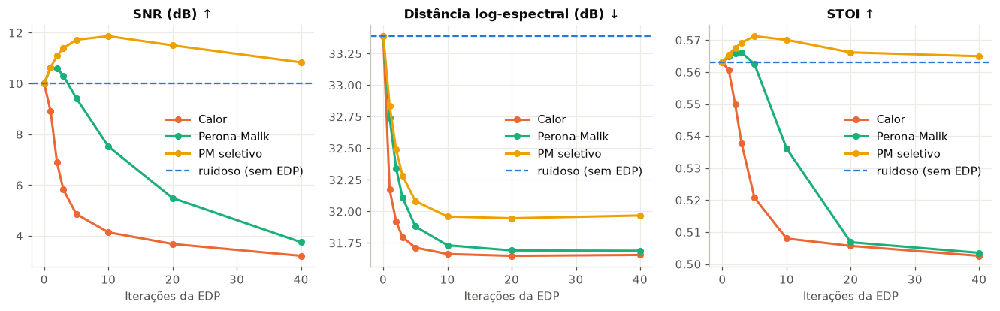

In [13]:
df = L.varredura_iteracoes(y, y_ruid, ref, D=0.2, kappa=10.0, dt=0.2)
display(df.round(3))
fig = L.fig_curvas(df, base=L.metricas(y, y_ruid, ref), saida="outputs/nb_09_curvas_iteracoes.png"); plt.show()

## 9b. Reduzir ruído de verdade, e aplicar a EDP só onde há ruído

Os resultados acima mostram que as EDPs **puras** não removem ruído branco. Dois acréscimos para testar:

**(a) Wiener** — método clássico de redução de ruído. Estima o ruído nas pausas da fala (os 10 % de quadros de menor energia) e atenua cada bin
conforme a sua SNR local: $G=\xi/(1+\xi)$, com $\xi=\max(P_y/P_n-1,\,0)$. Serve de *baseline* honesto.

**(b) PM seletivo** — responde à ideia "aplicar só em alguns pontos". Uma **máscara** $M(t,f)\in[0,1]$ liga a difusão só onde o espectrograma
está perto do piso de ruído (+8 dB) e a desliga onde há fala:

$$u \leftarrow u + M\cdot\Delta\tau\cdot\nabla\!\cdot\!\big(c(\|\nabla u\|)\nabla u\big)$$

Também comparamos **Wiener + PM** (EDP como acabamento). Os `.wav` abaixo têm o **mesmo volume** (RMS) do áudio limpo, para a escuta ser justa.

,SNR_dB,LSD_dB,STOI
ruidoso,10.002,33.388,0.563
calor,5.825,31.796,0.538
perona_malik,10.301,32.110,0.566
wiener,16.374,23.438,0.568
wiener+pm,13.710,21.950,0.568
pm_seletivo,11.866,31.959,0.570


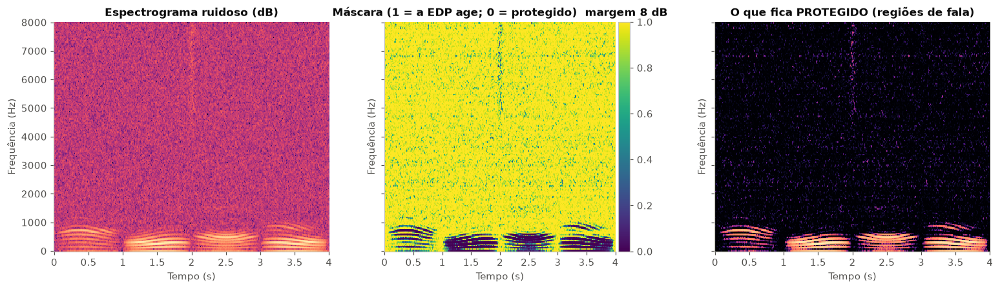

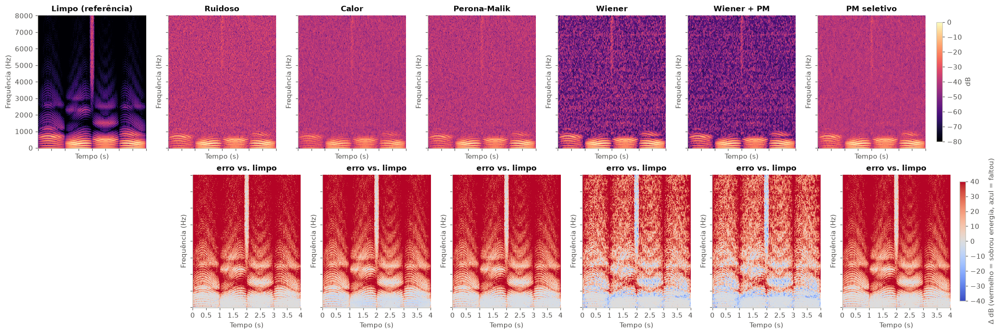

Ruidoso


calor


perona_malik


wiener


wiener+pm


pm_seletivo


In [14]:
res = L.variantes(y_ruid, D=0.2, kappa=10.0, dt=0.2, n_iter=3, n_iter_sel=10)
tab2 = {"ruidoso": L.metricas(y, y_ruid, ref)}
tab2.update({k: L.metricas(y, v["y_out"], ref) for k, v in res.items()})
display(pd.DataFrame(tab2).T.round(3))
fig = L.fig_mascara(y, y_ruid, saida="outputs/nb_11_mascara_seletiva.png"); plt.show()
fig = L.fig_variantes(y, y_ruid, res, saida="outputs/nb_10_todas_variantes.png"); plt.show()
print("Ruidoso"); display(Audio(L.igualar_nivel(y, y_ruid), rate=L.SR))
for k, v in res.items():
    print(k); display(Audio(L.igualar_nivel(y, v["y_out"]), rate=L.SR))

**Como ler:** compare SNR, LSD e STOI com a linha "ruidoso". Espere ver o **Wiener** melhorar bastante a SNR e a LSD, e o **PM seletivo** melhorar
pouco mas sem prejudicar a fala. O Wiener "cru" deixa um *ruído musical* (manchinhas isoladas no espectrograma); aplicar a EDP depois tende a
melhorar a LSD, mas pode reduzir a SNR. Confirme sempre **com áudio real e escutando**.

## 10. Leitura crítica e próximos passos

**O que esperar (e ver):**
* O espectrograma fica visivelmente mais "liso" e o LSD melhora um pouco, mas a **SNR de forma de onda pode piorar**: suavizar a magnitude
  apaga detalhe fino dos harmônicos, e a SNR é sensível a isso. A fase *ruidosa* também limita o resultado (no teste sintético, mesmo com a
  magnitude limpa perfeita, a fase ruidosa dá cerca de 23 dB de SNR, abaixo de um áudio limpo).
* **Calor** tem comportamento simples e previsível, mas degrada harmônicos já nas primeiras iterações. **Perona-Malik** aguenta mais iterações, mas
  deixa artefatos pontuais e depende de $\\kappa$.
* **A EDP regulariza, não "desliga" o ruído.** No gráfico da seção 7 o piso de ruído desce só ~1-2 dB: suavizar a imagem reduz a *variância* das flutuações,
  mas o *nível médio* do ruído de fundo permanece. Para realmente baixar o piso são necessárias técnicas como subtração espectral/Wiener; as EDPs podem entrar
  como uma etapa de *pós-processamento* (reduzir o "ruído musical") ou em tarefas como *inpainting*, onde brilham mais.
* Resultados com sinal sintético **não valem como conclusão sobre fala**: rode com áudio real (seção 1) e com vários locutores.

**Metodologia sugerida para o trabalho:**
1. Áudios limpos de fala pt-BR (ex.: LapsBM, Constituição) → sem ruído de fundo.
2. Ruído **controlado** (branco, rosa, "babble") em SNR de 20, 10, 5 e 0 dB — assim há referência limpa para medir.
3. Métodos: nenhum (baseline), calor, Perona-Malik (e baselines clássicos: filtro gaussiano, mediana, subtração espectral).
4. Varredura de hiperparâmetros ($D$, $\kappa$, $\Delta t$, iterações, n_fft) em um conjunto de **validação**; relatar no conjunto de **teste**.
5. Métricas: SNR, LSD, STOI (+ PESQ e, idealmente, teste de escuta) com **média ± desvio** entre locutores.
6. Extensões: *inpainting* (apagar um trecho e preencher via calor), difusão com tensor de estrutura, EDP em escala **mel**, fase estimada (Griffin-Lim).

O script `run_lab.py --benchmark` já executa os itens 2-3 e 5 em vários áudios.